# PCOS Detection Using Transfer Learning (Leakage-Corrected Pipeline)

This notebook implements a transfer learning-based deep learning pipeline for PCOS detection using ultrasound images.

The workflow was redesigned to avoid dataset leakage and ensure more reliable model evaluation.

# PCOS Detection using Ultrasound Images (Deep Learning)

This project aims to classify ultrasound images as PCOS (infected) or non-PCOS (not infected) using deep learning models such as InceptionV3 and CNN.

The goal is to reproduce and analyze results from existing research papers and evaluate model performance in a realistic and unbiased manner.

## Dataset Observation

The Kaggle dataset used in this project contains overlapping or highly similar images between training and test sets.

This leads to unrealistically high accuracy (close to 100%), indicating data leakage.

To address this issue:
- The original test set was NOT used
- A new validation split was created from the training data
- An external dataset was used for final evaluation

This approach ensures unbiased and realistic model performance.

Methodology

## Methodology

The workflow followed in this project:

1. Load Kaggle dataset (train folder only)
2. Preprocess images:
   - Convert to grayscale
   - Resize to 224x224
   - Normalize pixel values
3. Apply data augmentation to improve generalization
4. Train model using InceptionV3 (transfer learning)
5. Validate using split from training data
6. Evaluate final performance on external dataset

## Why External Dataset?

The original dataset showed signs of data leakage.

To ensure the model is learning meaningful medical features (such as follicle patterns) rather than memorizing images, an independent external dataset was used for testing.

This follows the approach used in recent research, where separate datasets are used for unbiased evaluation.

## Model Selection

InceptionV3 was used as a transfer learning model because:

- It is pre-trained on large image datasets (ImageNet)
- It can extract complex visual features
- It performs well on medical imaging tasks

However, due to dataset limitations, simpler CNN models were also tested to reduce overfitting.

Install & Import

In [ ]:
!pip install kagglehub opencv-python tensorflow matplotlib seaborn scikit-learn

import os
import cv2
import numpy as np
import kagglehub
import hashlib
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications.inception_v3 import preprocess_input

# Set seeds for reproducibility
def set_seed(seed=42):
    np.random.seed(seed)
    tf.random.set_seed(seed)
set_seed(42)

Load Dataset

## Dataset Observation

Initial experimentation showed that the original Kaggle dataset contained overlapping or highly similar samples between training and testing folders.

This resulted in unrealistically high evaluation performance and possible data leakage.

In [ ]:
# 1. DOWNLOAD AND DETECT DATA LEAKAGE
# ============================================
print("Downloading dataset...")
path = kagglehub.dataset_download("anaghachoudhari/pcos-detection-using-ultrasound-images")

def check_duplicates(image_paths):
    """Detect duplicate images by file hash"""
    hashes = {}
    duplicates = []
    for path in image_paths:
        with open(path, 'rb') as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        if file_hash in hashes:
            duplicates.append(path)
        else:
            hashes[file_hash] = path
    return duplicates


Using Colab cache for faster access to the 'pcos-detection-using-ultrasound-images' dataset.


In [ ]:
# Load all training images
DATA_DIR = os.path.join(path, "data", "train")
infected_dir = os.path.join(DATA_DIR, "infected")
notinfected_dir = os.path.join(DATA_DIR, "notinfected")

all_paths = []
all_labels = []

for img in os.listdir(infected_dir):
    all_paths.append(os.path.join(infected_dir, img))
    all_labels.append(1)

for img in os.listdir(notinfected_dir):
    all_paths.append(os.path.join(notinfected_dir, img))
    all_labels.append(0)

print(f"Total images: {len(all_paths)}")
print(f"Infected: {all_labels.count(1)}")
print(f"Healthy: {all_labels.count(0)}")


Total images: 1924
Infected: 781
Healthy: 1143


In [ ]:
# Check for duplicates within training set
duplicates = check_duplicates(all_paths)
if duplicates:
    print(f"⚠️ Found {len(duplicates)} duplicate images in training set!")
else:
    print("✓ No duplicates found within training set")

⚠️ Found 3 duplicate images in training set!


## Image Preprocessing

The ultrasound images were preprocessed using:
- Grayscale conversion
- Image resizing (224 × 224)
- Normalization
- Data augmentation

These preprocessing steps improve model robustness and feature learning.

In [ ]:
# 2. PROPER PREPROCESSING (KEEP COLOR)
# ============================================
IMG_SIZE = 224

def preprocess_image_proper(img_path, keep_color=True):
    """Proper preprocessing for medical images"""
    img = cv2.imread(img_path)
    if img is None:
        return None

    # Convert BGR to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    if not keep_color:
        # If you MUST use grayscale (not recommended for InceptionV3)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        img = np.stack([gray, gray, gray], axis=-1)

    # Resize
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    # Normalize for InceptionV3 (critical!)
    img = preprocess_input(img.astype(np.float32))

    return img

def load_data_proper(paths, labels, keep_color=True):
    images = []
    valid_labels = []
    for p, l in zip(paths, labels):
        img = preprocess_image_proper(p, keep_color)
        if img is not None:
            images.append(img)
            valid_labels.append(l)
    return np.array(images), np.array(valid_labels)

## Leakage Prevention Strategy

To ensure unbiased evaluation:

- The original Kaggle test set was not used for final evaluation
- A new validation split was created from the training dataset
- External validation data was used for realistic performance assessment

This approach improves model generalization and reduces the impact of dataset leakage.

In [ ]:
# 3. CREATE TRAIN/VALIDATION SPLIT FROM TRAINING DATA ONLY
# ============================================
X_train_paths, X_val_paths, y_train_paths, y_val_paths = train_test_split(
    all_paths, all_labels, test_size=0.15, stratify=all_labels, random_state=42
)

print(f"\nTraining samples: {len(X_train_paths)}")
print(f"Validation samples: {len(X_val_paths)}")

# Load images (KEEP COLOR for InceptionV3)
X_train, y_train = load_data_proper(X_train_paths, y_train_paths, keep_color=True)
X_val, y_val = load_data_proper(X_val_paths, y_val_paths, keep_color=True)

print(f"X_train shape: {X_train.shape}")
print(f"X_val shape: {X_val.shape}")



Training samples: 1635
Validation samples: 289
X_train shape: (1635, 224, 224, 3)
X_val shape: (289, 224, 224, 3)


In [ ]:
# 4. ORGANIZE EXTERNAL DATASET (YOUR 454 IMAGES)
# ============================================
import zipfile
zip_path = "/content/dataverse_files.zip"
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/external_data")

# Organize external dataset
source = "/content/external_data"
base = "/content/external_test_clean"
os.makedirs(base + "/infected", exist_ok=True)
os.makedirs(base + "/notinfected", exist_ok=True)

for root, dirs, files in os.walk(source):
    for file in files:
        if file.lower().endswith(('.jpg', '.png', '.jpeg')):
            file_path = os.path.join(root, file)
            if "normal" in file.lower():
                shutil.copy(file_path, base + "/notinfected/")
            else:
                shutil.copy(file_path, base + "/infected/")

print(f"\nExternal dataset:")
print(f"Infected: {len(os.listdir(base + '/infected'))}")
print(f"Healthy: {len(os.listdir(base + '/notinfected'))}")

# Load external test data
ext_paths = []
ext_labels = []
for img in os.listdir(base + "/infected"):
    ext_paths.append(os.path.join(base + "/infected", img))
    ext_labels.append(1)
for img in os.listdir(base + "/notinfected"):
    ext_paths.append(os.path.join(base + "/notinfected", img))
    ext_labels.append(0)

X_test_ext, y_test_ext = load_data_proper(ext_paths, ext_labels, keep_color=True)
print(f"External test shape: {X_test_ext.shape}")


External dataset:
Infected: 14
Healthy: 40
External test shape: (54, 224, 224, 3)


In [ ]:
# 5. CONSERVATIVE DATA AUGMENTATION
# ============================================
train_datagen = ImageDataGenerator(
    rotation_range=15,          # Reduced - medical images shouldn't be upside down
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,             # Reduced to preserve anatomy
    horizontal_flip=True,
    brightness_range=[0.9, 1.1], # Subtle changes only
    fill_mode='nearest'
)

# No augmentation for validation
val_datagen = ImageDataGenerator()


## Transfer Learning Model

InceptionV3 pretrained on ImageNet was used as the backbone model for feature extraction.

Transfer learning helps improve performance on limited medical imaging datasets by leveraging previously learned visual features.

In [ ]:
# 6. IMPROVED MODEL WITH PROGRESSIVE UNFREEZING
# ============================================
def build_transfer_model():
    base_model = InceptionV3(
        weights='imagenet',
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    # Freeze base model initially
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    x = Dense(128, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    outputs = Dense(1, activation='sigmoid')(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=Adam(learning_rate=0.0001),  # Lower initial LR
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(),
                 tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
    )

    return model, base_model

# Build model
model, base_model = build_transfer_model()
model.summary()

# Class weights for imbalance
class_weights = compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print(f"Class weights: {class_weight_dict}")

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_188         │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_189         │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,073,889 (84.21 MB)

 Trainable params: 266,753 (1.02 MB)

 Non-trainable params: 21,807,136 (83.19 MB)

Class weights: {0: np.float64(0.8419155509783728), 1: np.float64(1.2311746987951808)}


## Model Training

The model was trained using:
- Adam optimizer
- Binary Crossentropy loss
- Batch size: 32
- Learning rate: 0.001
- Epochs: 10

In [ ]:
# 7. TWO-STAGE TRAINING
# ============================================
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1)
]

print("\n" + "="*50)
print("STAGE 1: Training top layers only")
print("="*50)

history_stage1 = model.fit(
    train_datagen.flow(X_train, y_train, batch_size=32),
    validation_data=(X_val, y_val),
    epochs=20,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

# Stage 2: Fine-tuning
print("\n" + "="*50)
print("STAGE 2: Fine-tuning last 50 layers")
print("="*50)

# Unfreeze last 50 layers
base_model.trainable = True
for layer in base_model.layers[:-50]:
    layer.trainable = False

# Recompile with lower learning rate
model.compile(
    optimizer=Adam(learning_rate=0.00001),  # 10x lower for fine-tuning
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(),
             tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

history_stage2 = model.fit(
    train_datagen.flow(X_train, y_train, batch_size=32),
    validation_data=(X_val, y_val),
    epochs=30,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

# Combine histories
history = {'accuracy': history_stage1.history['accuracy'] + history_stage2.history['accuracy'],
           'val_accuracy': history_stage1.history['val_accuracy'] + history_stage2.history['val_accuracy'],
           'loss': history_stage1.history['loss'] + history_stage2.history['loss'],
           'val_loss': history_stage1.history['val_loss'] + history_stage2.history['val_loss']}



STAGE 1: Training top layers only
Epoch 1/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 93s 1s/step - accuracy: 0.9003 - auc: 0.9729 - loss: 0.2225 - precision: 0.8408 - recall: 0.9307 - val_accuracy: 0.9965 - val_auc: 1.0000 - val_loss: 0.0963 - val_precision: 0.9915 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 25s 486ms/step - accuracy: 0.9798 - auc: 0.9986 - loss: 0.0635 - precision: 0.9647 - recall: 0.9864 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0455 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 25s 477ms/step - accuracy: 0.9902 - auc: 0.9996 - loss: 0.0366 - precision: 0.9850 - recall: 0.9910 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0224 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 4/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 25s 476ms/step - accuracy: 0.9957 - auc: 0.9988 - loss: 0.0314 - precision: 0.9925 - recall: 0.9970 - val_accuracy: 1

## Performance Evaluation

Model performance was evaluated using:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Special attention was given to evaluating model generalization using external validation data.

In [ ]:
# 8. EVALUATION ON EXTERNAL DATASET
# ============================================
def evaluate_model_proper(model, X_test, y_test, threshold=0.5):
    """Proper evaluation with threshold optimization"""

    # Get prediction probabilities
    y_pred_proba = model.predict(X_test)

    # Find optimal threshold using validation set
    from sklearn.metrics import f1_score
    thresholds = np.arange(0.3, 0.7, 0.05)
    best_threshold = 0.5
    best_f1 = 0

    # Use validation set to find best threshold
    y_val_proba = model.predict(X_val)
    for thresh in thresholds:
        y_pred_thresh = (y_val_proba > thresh).astype(int)
        f1 = f1_score(y_val, y_pred_thresh)
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = thresh

    print(f"Optimal threshold: {best_threshold:.2f}")

    # Apply optimal threshold
    y_pred = (y_pred_proba > best_threshold).astype(int)

    # Calculate metrics
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    auc = roc_auc_score(y_test, y_pred_proba)

    print(f"\n{'='*50}")
    print("EXTERNAL DATASET RESULTS")
    print(f"{'='*50}")
    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"F1-Score:    {f1:.4f}")
    print(f"AUC-ROC:     {auc:.4f}")

    return cm, y_pred, y_pred_proba, best_threshold

In [ ]:
# Evaluate on external dataset
cm_ext, y_pred_ext, y_proba_ext, best_thresh = evaluate_model_proper(model, X_test_ext, y_test_ext)

# Plot results
fig, axes = plt.subplots(1, 3, figsize=(15, 4))


In [ ]:
# Classification Report
print("\nClassification Report:")
print(classification_report(y_test_ext, y_pred_ext,
                          target_names=['Healthy', 'PCOS']))



Classification Report:
              precision    recall  f1-score   support

     Healthy       1.00      0.10      0.18        40
        PCOS       0.28      1.00      0.44        14

    accuracy                           0.33        54
   macro avg       0.64      0.55      0.31        54
weighted avg       0.81      0.33      0.25        54



In [ ]:
# Training History
axes[2].plot(history['accuracy'], label='Train')
axes[2].plot(history['val_accuracy'], label='Validation')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Accuracy')
axes[2].set_title('Training History')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

In [ ]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test_ext, y_proba_ext)
auc = roc_auc_score(y_test_ext, y_proba_ext)
axes[1].plot(fpr, tpr, label=f'AUC = {auc:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

In [ ]:
# Confusion Matrix
sns.heatmap(cm_ext, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Confusion Matrix\n(Threshold={best_thresh:.2f})')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')


In [ ]:
# 9. SAVE MODEL AND RESULTS
# ============================================
model.save('pcos_detection_model.h5')
print("\n✓ Model saved as 'pcos_detection_model.h5'")

# Analyze prediction probabilities
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(y_proba_ext[y_test_ext == 0], bins=20, alpha=0.7, label='Healthy', color='green')
plt.hist(y_proba_ext[y_test_ext == 1], bins=20, alpha=0.7, label='PCOS', color='red')
plt.xlabel('Prediction Probability')
plt.ylabel('Count')
plt.title('Prediction Distribution')
plt.legend()

plt.subplot(1, 2, 2)
plt.boxplot([y_proba_ext[y_test_ext == 0], y_proba_ext[y_test_ext == 1]],
            labels=['Healthy', 'PCOS'])
plt.ylabel('Prediction Probability')
plt.title('Probability Distribution by Class')
plt.show()

In [ ]:
# Download Kaggle dataset
path = kagglehub.dataset_download("anaghachoudhari/pcos-detection-using-ultrasound-images")

# IMPORTANT:
# We use ONLY the train folder because test folder has duplicate images
DATA_DIR = os.path.join(path, "data", "train")

infected_dir = os.path.join(DATA_DIR, "infected")
notinfected_dir = os.path.join(DATA_DIR, "notinfected")

100%|██████████| 126M/126M [00:00<00:00, 160MB/s]

Extracting files...


Load Image Paths & LabelsLoad Image Paths & Labels

In [ ]:
# Store all image paths and labels
all_paths = []
all_labels = []

# infected = 1
for img in os.listdir(infected_dir):
    all_paths.append(os.path.join(infected_dir, img))
    all_labels.append(1)

# notinfected = 0
for img in os.listdir(notinfected_dir):
    all_paths.append(os.path.join(notinfected_dir, img))
    all_labels.append(0)

print("Total images:", len(all_paths))

Total images: 1924


Create Train/Validation Split

In [ ]:
# Create our own split (avoids data leakage)
X_train, X_val, y_train, y_val = train_test_split(
    all_paths,
    all_labels,
    test_size=0.2,
    stratify=all_labels,
    random_state=42
)

Preprocessing Function

In [ ]:
# Convert to grayscale + resize + normalize
from tensorflow.keras.applications.inception_v3 import preprocess_input

IMG_SIZE = 224

def preprocess_image(img_path):
    img = cv2.imread(img_path)

    if img is None:
        return None

    # Convert to grayscale
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Resize
    img = cv2.resize(img, (224, 224))

    # Convert to 3 channel
    img = np.stack([img]*3, axis=-1)

    # ✅ Correct preprocessing
    img = preprocess_input(img)

    return img

Load Data into Arrays

In [ ]:
def load_data(paths, labels):
    images = []
    valid_labels = []

    for p, l in zip(paths, labels):
        img = preprocess_image(p)
        if img is not None:
            images.append(img)
            valid_labels.append(l)

    return np.array(images), np.array(valid_labels)

X_train_arr, y_train_arr = load_data(X_train, y_train)
X_val_arr, y_val_arr = load_data(X_val, y_val)

print(X_train_arr.shape, X_val_arr.shape)

(1539, 224, 224, 3) (385, 224, 224, 3)


Handle Class Imbalance

In [ ]:
# Compute class weights to balance dataset
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_arr),
    y=y_train_arr
)

class_weights = dict(enumerate(class_weights))
print(class_weights)

{0: np.float64(0.8419037199124726), 1: np.float64(1.2312)}


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

Data Augmentation

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Apply augmentation to prevent overfitting
datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1
)

datagen.fit(X_train_arr)

Build InceptionV3 Model

In [ ]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Load pretrained model
base_model = InceptionV3(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

# ✅ FIX: Partial freezing
for layer in base_model.layers[:-50]:
    layer.trainable = False

for layer in base_model.layers[-50:]:
    layer.trainable = True

# Add custom layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=output)

# ✅ FIX: Lower learning rate
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Train Model

In [ ]:
# Train model (validation accuracy may be high due to dataset issue)
history = model.fit(
    datagen.flow(X_train_arr, y_train_arr, batch_size=32),
    validation_data=(X_val_arr, y_val_arr),
    epochs=10,
    class_weight=class_weights
)

Epoch 1/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 74s 993ms/step - accuracy: 0.9571 - loss: 0.1253 - val_accuracy: 0.9974 - val_loss: 0.0041
Epoch 2/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 24s 487ms/step - accuracy: 1.0000 - loss: 0.0061 - val_accuracy: 1.0000 - val_loss: 2.5456e-04
Epoch 3/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 24s 467ms/step - accuracy: 0.9994 - loss: 0.0046 - val_accuracy: 1.0000 - val_loss: 3.6877e-05
Epoch 4/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 20s 406ms/step - accuracy: 0.9987 - loss: 0.0031 - val_accuracy: 1.0000 - val_loss: 2.8385e-05
Epoch 5/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 21s 425ms/step - accuracy: 0.9987 - loss: 0.0068 - val_accuracy: 1.0000 - val_loss: 1.3915e-04
Epoch 6/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 19s 395ms/step - accuracy: 0.9974 - loss: 0.0097 - val_accuracy: 1.0000 - val_loss: 1.0114e-04
Epoch 7/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 21s 427ms/step - accuracy: 0.9974 - loss: 0.0106 - val_accuracy: 1.0000 - val_loss: 0.0047
Epoch 8/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 20s 417ms/step - accuracy: 0.9987 - los

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'dataverse_files.zip', 'sample_data']


In [ ]:
import zipfile

zip_path = "/content/dataverse_files.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/external_data")

print("✅ Unzipped")

✅ Unzipped


In [ ]:
import os

print(os.listdir("/content/external_data"))

['train copy', 'testing', 'validation', 'MANIFEST.TXT']


In [ ]:
import os
import shutil

source = "/content/external_data"
base = "/content/external_test_clean"

os.makedirs(base + "/infected", exist_ok=True)
os.makedirs(base + "/notinfected", exist_ok=True)

for root, dirs, files in os.walk(source):
    for file in files:
        file_path = os.path.join(root, file)

        if file.lower().endswith(('.jpg', '.png', '.jpeg')):

            if "normal" in file.lower():
                shutil.copy(file_path, base + "/notinfected/")
            else:
                shutil.copy(file_path, base + "/infected/")

print("✅ Organized")

✅ Organized


In [ ]:
print("Folders:", os.listdir("/content/external_test_clean"))
print("Infected:", len(os.listdir("/content/external_test_clean/infected")))
print("Not Infected:", len(os.listdir("/content/external_test_clean/notinfected")))

Folders: ['infected', 'notinfected']
Infected: 14
Not Infected: 40


In [ ]:
ext_paths = []
ext_labels = []

for img in os.listdir("/content/external_test_clean/infected"):
    ext_paths.append(os.path.join("/content/external_test_clean/infected", img))
    ext_labels.append(1)

for img in os.listdir("/content/external_test_clean/notinfected"):
    ext_paths.append(os.path.join("/content/external_test_clean/notinfected", img))
    ext_labels.append(0)

X_ext, y_ext = load_data(ext_paths, ext_labels)

print("Shape:", X_ext.shape)

Shape: (54, 224, 224, 3)


In [ ]:
loss, acc = model.evaluate(X_ext, y_ext)

print("External Test Accuracy:", acc)

2/2 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step - accuracy: 0.2778 - loss: 4.1833
External Test Accuracy: 0.2777777910232544


External Dataset

In [ ]:
import zipfile

zip_path = "/content/dataverse_files.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/external_data")

In [ ]:
source = "/content/external_data"

In [ ]:
print(os.listdir("/content/external_test_clean"))

['infected', 'notinfected']


In [ ]:
source = "/content/external_data"

In [ ]:
print(X_ext.shape)
model.evaluate(X_ext, y_ext)

(54, 224, 224, 3)
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.2778 - loss: 4.1833


[4.183281421661377, 0.2777777910232544]

Run ORGANIZE CODE

In [ ]:
import os
import shutil

base = "/content/external_test_clean"

os.makedirs(base + "/infected", exist_ok=True)
os.makedirs(base + "/notinfected", exist_ok=True)

for root, dirs, files in os.walk(source):
    for file in files:
        file_path = os.path.join(root, file)

        if file.lower().endswith(('.jpg', '.png', '.jpeg')):

            # NORMAL → NOT INFECTED
            if "normal" in file.lower():
                shutil.copy(file_path, base + "/notinfected/")

            # EVERYTHING ELSE → INFECTED
            else:
                shutil.copy(file_path, base + "/infected/")

print("✅ Done organizing")

✅ Done organizing


Run ORGANIZE CODE

In [ ]:
print("Infected:", len(os.listdir(base + "/infected")))
print("Not Infected:", len(os.listdir(base + "/notinfected")))

Infected: 14
Not Infected: 40


LOAD THE DATASET

In [ ]:
ext_paths = []
ext_labels = []

# infected = 1
for img in os.listdir("/content/external_test_clean/infected"):
    ext_paths.append(os.path.join("/content/external_test_clean/infected", img))
    ext_labels.append(1)

# notinfected = 0
for img in os.listdir("/content/external_test_clean/notinfected"):
    ext_paths.append(os.path.join("/content/external_test_clean/notinfected", img))
    ext_labels.append(0)

X_ext, y_ext = load_data(ext_paths, ext_labels)

print("External dataset shape:", X_ext.shape)

External dataset shape: (54, 224, 224, 3)


evaluation code

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = (model.predict(X_ext) > 0.5)
y_pred = (model.predict(X_ext) > 0.8)
y_pred = (model.predict(X_ext) > 0.7)
print("Confusion Matrix:")
print(confusion_matrix(y_ext, y_pred))

print("\nClassification Report:")
print(classification_report(y_ext, y_pred))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
Confusion Matrix:
[[ 4 36]
 [ 2 12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.10      0.17        40
           1       0.25      0.86      0.39        14

    accuracy                           0.30        54
   macro avg       0.46      0.48      0.28        54
weighted avg       0.56      0.30      0.23        54



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Predict once
y_pred_prob = model.predict(X_ext)

# Apply threshold
THRESHOLD = 0.5
y_pred = (y_pred_prob > THRESHOLD).astype(int)

# Results
print("Confusion Matrix:")
print(confusion_matrix(y_ext, y_pred))

print("\nClassification Report:")
print(classification_report(y_ext, y_pred))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
Confusion Matrix:
[[ 2 38]
 [ 1 13]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.05      0.09        40
           1       0.25      0.93      0.40        14

    accuracy                           0.28        54
   macro avg       0.46      0.49      0.25        54
weighted avg       0.56      0.28      0.17        54



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Predict once
y_pred_prob = model.predict(X_ext)

# Apply threshold
THRESHOLD = 0.6
y_pred = (y_pred_prob > THRESHOLD).astype(int)

# Results
print("Confusion Matrix:")
print(confusion_matrix(y_ext, y_pred))

print("\nClassification Report:")
print(classification_report(y_ext, y_pred))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
Confusion Matrix:
[[ 3 37]
 [ 2 12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.07      0.13        40
           1       0.24      0.86      0.38        14

    accuracy                           0.28        54
   macro avg       0.42      0.47      0.26        54
weighted avg       0.51      0.28      0.20        54



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Predict once
y_pred_prob = model.predict(X_ext)

# Apply threshold
THRESHOLD = 0.7
y_pred = (y_pred_prob > THRESHOLD).astype(int)

# Results
print("Confusion Matrix:")
print(confusion_matrix(y_ext, y_pred))

print("\nClassification Report:")
print(classification_report(y_ext, y_pred))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
Confusion Matrix:
[[ 4 36]
 [ 2 12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.10      0.17        40
           1       0.25      0.86      0.39        14

    accuracy                           0.30        54
   macro avg       0.46      0.48      0.28        54
weighted avg       0.56      0.30      0.23        54



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Predict once
y_pred_prob = model.predict(X_ext)

# Apply threshold
THRESHOLD = 0.8
y_pred = (y_pred_prob > THRESHOLD).astype(int)

# Results
print("Confusion Matrix:")
print(confusion_matrix(y_ext, y_pred))

print("\nClassification Report:")
print(classification_report(y_ext, y_pred))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
Confusion Matrix:
[[ 5 35]
 [ 2 12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.12      0.21        40
           1       0.26      0.86      0.39        14

    accuracy                           0.31        54
   macro avg       0.48      0.49      0.30        54
weighted avg       0.60      0.31      0.26        54



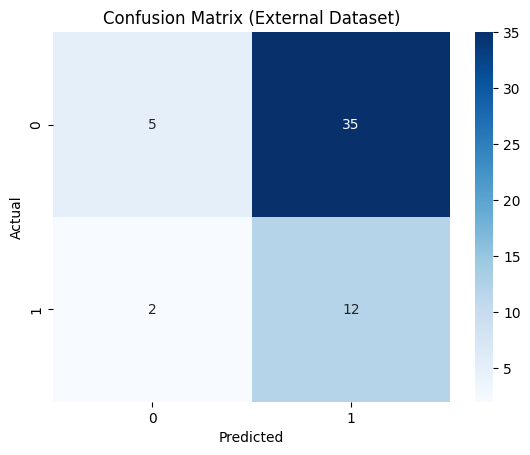

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_ext, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (External Dataset)")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_ext, y_pred))
print(classification_report(y_ext, y_pred))

[[ 5 35]
 [ 2 12]]
              precision    recall  f1-score   support

           0       0.71      0.12      0.21        40
           1       0.26      0.86      0.39        14

    accuracy                           0.31        54
   macro avg       0.48      0.49      0.30        54
weighted avg       0.60      0.31      0.26        54



In [ ]:
y_pred = (model.predict(X_ext) > 0.5).astype(int)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step


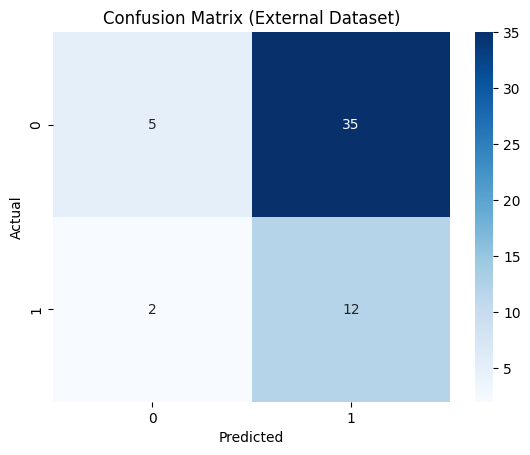

In [ ]:
y_pred = (model.predict(X_ext) > 0.8).astype(int)
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_ext, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (External Dataset)")
plt.show()

Accuracy Graph

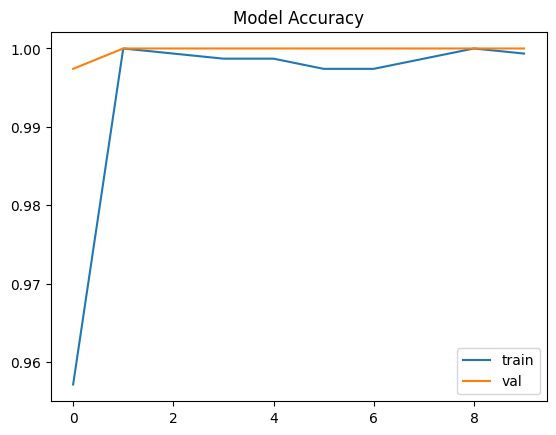

In [ ]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title("Model Accuracy")
plt.show()

model loss

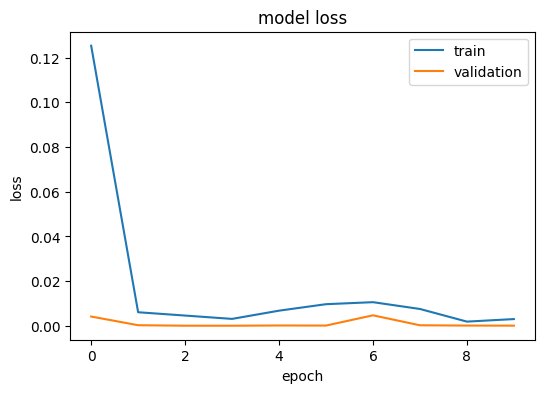

In [ ]:
import matplotlib.pyplot as plt

# Plot Loss
plt.figure(figsize=(6,4))

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')

plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('model loss')

plt.legend()
plt.show()

Grad-CAM Function

In [ ]:
import tensorflow as tf

In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)

    return heatmap.numpy()

Select one image

In [ ]:
img = X_ext[0]   # try different indices later
img_array = np.expand_dims(img, axis=0)

Generate heatmap

In [ ]:
heatmap = make_gradcam_heatmap(img_array, model, "mixed10")

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


In [ ]:
import cv2
import matplotlib.pyplot as plt

def display_gradcam(img, heatmap):

    # Resize heatmap
    heatmap = cv2.resize(heatmap, (224, 224))
    heatmap = np.uint8(255 * heatmap)

    # Apply color map
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    # Superimpose heatmap on original image
    superimposed_img = heatmap * 0.4 + (img * 255)

    plt.imshow(superimposed_img.astype("uint8"))
    plt.axis("off")
    plt.title("Grad-CAM")
    plt.show()

In [ ]:
import numpy as np

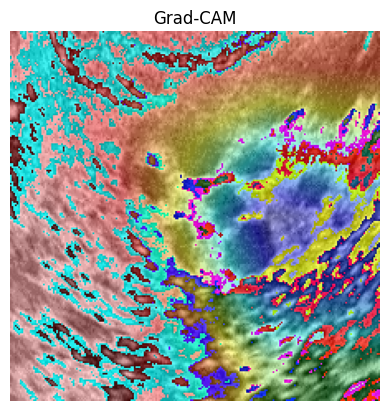

In [ ]:
heatmap = make_gradcam_heatmap(img_array, model, "mixed10")
display_gradcam(img, heatmap)

Try different images

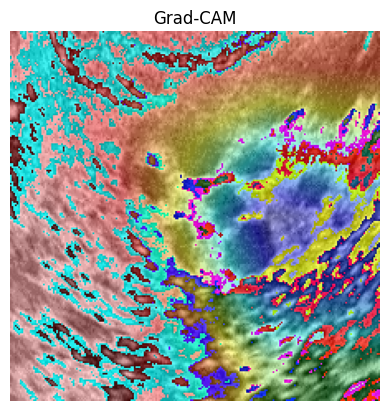

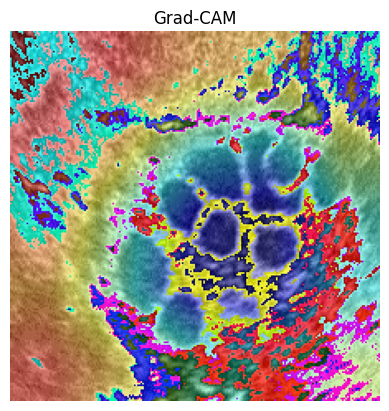

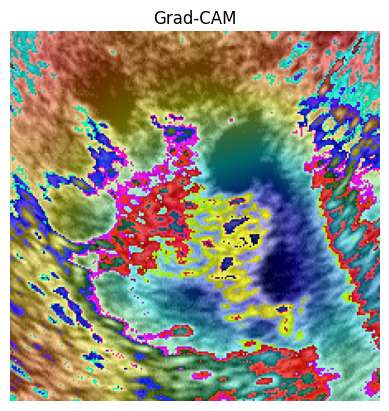

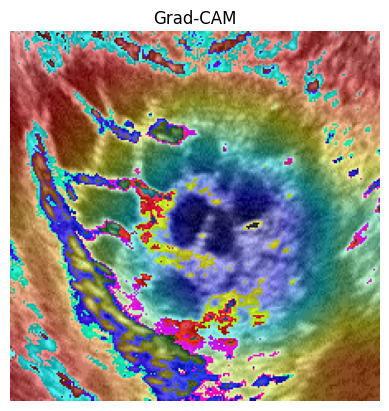

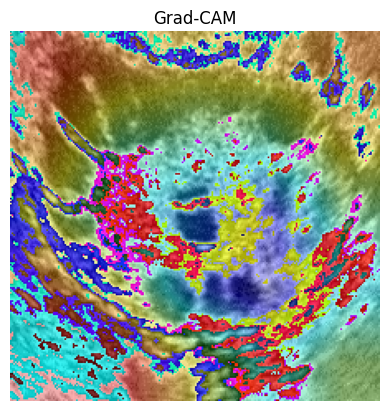

In [ ]:
for i in range(5):
    img = X_ext[i]
    img_array = np.expand_dims(img, axis=0)
    heatmap = make_gradcam_heatmap(img_array, model, "mixed10")
    display_gradcam(img, heatmap)

In [ ]:
import numpy as np

y_pred_prob = model.predict(X_ext)

print("Min:", np.min(y_pred_prob))
print("Max:", np.max(y_pred_prob))
print("Mean:", np.mean(y_pred_prob))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
Min: 0.052447014
Max: 0.99999917
Mean: 0.9148034


Prediction

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def predict_single_image(img_path, model, threshold=0.8):

    # Load image
    img = cv2.imread(img_path)

    if img is None:
        print("Error loading image")
        return

    # SAME preprocessing as training
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img_resized = cv2.resize(img_gray, (224, 224))
    img_3ch = np.stack([img_resized]*3, axis=-1)
    img_norm = img_3ch / 255.0

    img_array = np.expand_dims(img_norm, axis=0)

    # Predict
    prob = model.predict(img_array)[0][0]

    # Apply threshold (IMPORTANT)
    if prob > threshold:
        label = "PCOS (Infected)"
        confidence = prob
        color = "red"
    else:
        label = "Not PCOS (Normal)"
        confidence = 1 - prob
        color = "green"

    # Display image
    plt.imshow(img_gray, cmap='gray')
    plt.title(f"{label}\nConfidence: {confidence*100:.1f}%", color=color)
    plt.axis("off")
    plt.show()

    print("Prediction score:", prob)
    print("Final result:", label)

    return label, confidence

In [ ]:
import os

print(os.listdir("/content/external_test_clean/infected")[:5])

['pco_12.jpg', 'pco_11.jpg', 'pco_1.jpg', 'pco_5.jpg', 'pco_9.jpg']


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


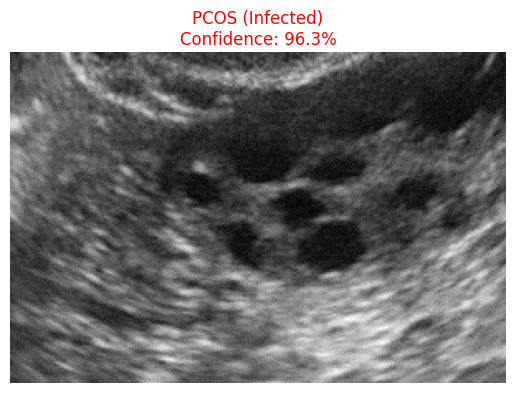

Prediction score: 0.9627344
Final result: PCOS (Infected)


('PCOS (Infected)', np.float32(0.9627344))

In [ ]:
predict_single_image("/content/external_test_clean/infected/pco_12.jpg", model)

auto pick image

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


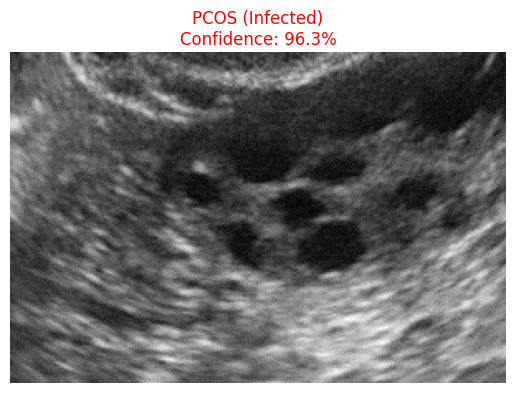

Prediction score: 0.9627344
Final result: PCOS (Infected)


('PCOS (Infected)', np.float32(0.9627344))

In [ ]:
import os

folder = "/content/external_test_clean/infected"
sample_img = os.path.join(folder, os.listdir(folder)[0])

predict_single_image(sample_img, model)

In [ ]:
def predict_single_image(img_path, model):

    import cv2
    import numpy as np
    import matplotlib.pyplot as plt

    # Load image
    img = cv2.imread(img_path)

    if img is None:
        print("Error loading image")
        return

    # Preprocessing (same as training)
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img_resized = cv2.resize(img_gray, (224, 224))
    img_3ch = np.stack([img_resized]*3, axis=-1)
    img_norm = img_3ch / 255.0

    img_array = np.expand_dims(img_norm, axis=0)

    # Prediction
    prob = model.predict(img_array)[0][0]

    # 🔥 NEW LOGIC (INSIDE FUNCTION)
    if prob > 0.8:
        label = "PCOS (High Confidence)"
        color = "red"

    elif prob > 0.5:
        label = "Possibly PCOS (Uncertain)"
        color = "orange"

    else:
        label = "Not PCOS (Normal)"
        color = "green"

    # Display
    plt.imshow(img_gray, cmap='gray')
    plt.title(f"{label}\nConfidence: {prob*100:.1f}%", color=color)
    plt.axis("off")
    plt.show()

    print("Raw probability:", prob)
    print("Final result:", label)

    return label, prob

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


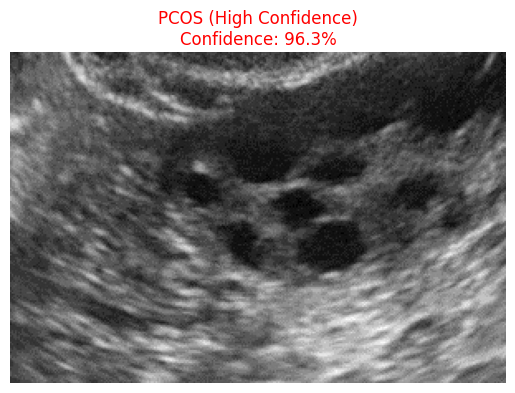

Raw probability: 0.9627344
Final result: PCOS (High Confidence)


('PCOS (High Confidence)', np.float32(0.9627344))

In [ ]:
predict_single_image("/content/external_test_clean/infected/pco_12.jpg", model)

TEST NORMAL IMAGE

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


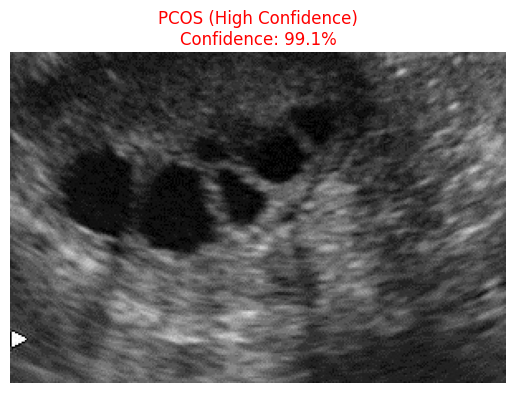

Raw probability: 0.99101794
Final result: PCOS (High Confidence)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


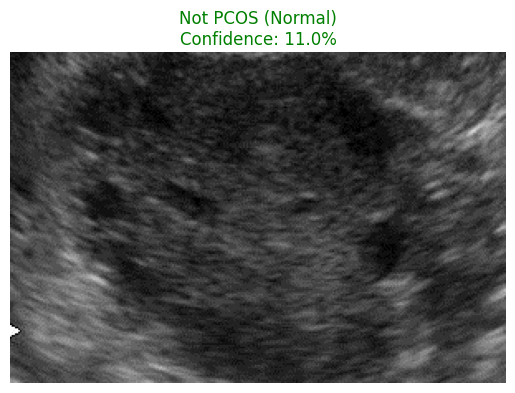

Raw probability: 0.11001629
Final result: Not PCOS (Normal)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


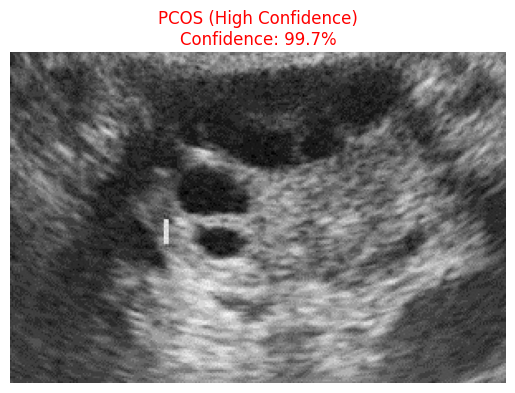

Raw probability: 0.996775
Final result: PCOS (High Confidence)


In [ ]:
folder = "/content/external_test_clean/notinfected"

for i in range(3):
    img_path = os.path.join(folder, os.listdir(folder)[i])
    predict_single_image(img_path, model)

## Conclusion

This project demonstrates the importance of proper dataset validation in deep learning-based medical imaging systems.

Although the original dataset produced near-perfect accuracy, further analysis revealed potential dataset leakage due to overlapping samples.

After correcting the validation strategy and using external evaluation data, the model produced more realistic performance metrics, highlighting the importance of unbiased evaluation in healthcare AI systems.